## Persiapan

In [1]:
import collections
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "Tugas" else Path.cwd()
MENTAH = ROOT / "Dataset" / "tugas"
HASIL = ROOT / "Dataset" / "paper"
HASIL.mkdir(parents=True, exist_ok=True)

AMBANG_LABEL = 100

print("Folder data :", MENTAH.relative_to(ROOT))
print("Folder hasil:", HASIL.relative_to(ROOT))
print("Ambang label:", AMBANG_LABEL, "soal")

Folder data : Dataset/tugas
Folder hasil: Dataset/paper
Ambang label: 100 soal


**Penjelasan.** `AMBANG_LABEL` menentukan tag mana yang layak dipakai sebagai label. Tag yang muncul di kurang dari seratus soal dibuang karena terlalu sedikit contohnya untuk dilatih.

## Membaca Hasil Scraping

In [2]:
semua = pd.read_csv(MENTAH / "leetcode_soal.csv")
semua["tags"] = semua["Topic Tags"].fillna("").apply(
    lambda s: [t.strip() for t in s.split(",") if t.strip()])

print("Jumlah soal :", f"{len(semua):,}")
print("Kolom       :", [k for k in semua.columns if k != "tags"])
print("\nSebaran Difficulty")
for kelas, n in semua["Difficulty"].value_counts().items():
    print(f"  {kelas:<8} {n:>5}  ({100 * n / len(semua):>4.1f} persen)")

jumlah = semua["tags"].apply(len)
print("\nJumlah tag per soal")
print(f"  rata rata      : {jumlah.mean():.2f}")
print(f"  tanpa tag      : {(jumlah == 0).sum():,}")
print(f"  tepat 1 tag    : {(jumlah == 1).sum():,}")
print(f"  2 tag ke atas  : {(jumlah >= 2).sum():,}")
print(f"  terbanyak      : {jumlah.max()} tag")

Jumlah soal : 3,284
Kolom       : ['Problem ID', 'Problem Name', 'Slug', 'Difficulty', 'Topic Tags', 'Jumlah Tag', 'Ada Gambar', 'Description']

Sebaran Difficulty
  Medium    1660  (50.5 persen)
  Easy       839  (25.5 persen)
  Hard       785  (23.9 persen)

Jumlah tag per soal
  rata rata      : 3.30
  tanpa tag      : 64
  tepat 1 tag    : 317
  2 tag ke atas  : 2,903
  terbanyak      : 15 tag


**Penjelasan.** Inti persoalannya ada di baris terakhir. Dari 3.284 soal, hanya 317 yang bertag tunggal, sedangkan 2.903 soal membawa dua tag atau lebih. Jadi kolom topik memang multi-label sejak awal, bukan single-label yang kebetulan berantakan.

## Dataset I, Target Difficulty

In [3]:
dataset1 = semua[["Problem ID", "Problem Name", "Slug", "Description", "Difficulty"]].copy()
dataset1 = dataset1.dropna(subset=["Description", "Difficulty"]).reset_index(drop=True)
dataset1.to_csv(HASIL / "dataset1_difficulty.csv", index=False)

print("Dataset I")
print("  jumlah soal :", f"{len(dataset1):,}")
print("  kolom target: Difficulty")
print("  kelas       :", dataset1["Difficulty"].nunique())
for kelas, n in dataset1["Difficulty"].value_counts().items():
    print(f"    {kelas:<8} {n:>5}  ({100 * n / len(dataset1):>4.1f} persen)")
rasio = dataset1["Difficulty"].value_counts()
print(f"  rasio terbesar banding terkecil: {rasio.iloc[0] / rasio.iloc[-1]:.1f}")
print("\nTersimpan:", (HASIL / "dataset1_difficulty.csv").name)

Dataset I
  jumlah soal : 3,284
  kolom target: Difficulty
  kelas       : 3
    Medium    1660  (50.5 persen)
    Easy       839  (25.5 persen)
    Hard       785  (23.9 persen)
  rasio terbesar banding terkecil: 2.1

Tersimpan: dataset1_difficulty.csv


**Penjelasan.** Tingkat kesulitan sudah tersedia langsung dari API LeetCode untuk setiap soal, jadi tidak perlu pelabelan manual sama sekali dan seluruh 3.284 soal bisa dipakai. Targetnya single-label karena satu soal memang hanya punya satu tingkat kesulitan. Kelasnya tetap tidak seimbang, Medium menguasai separuh data.

## Dataset II, Target Category

In [4]:
hitung = collections.Counter(t for daftar in semua["tags"] for t in daftar)
label_dipakai = sorted(t for t, n in hitung.items() if n >= AMBANG_LABEL)

dataset2 = semua[["Problem ID", "Problem Name", "Slug", "Description"]].copy()
dataset2["Category"] = semua["tags"].apply(
    lambda l: [t for t in l if t in label_dipakai])
dataset2 = dataset2[dataset2["Category"].apply(len) > 0]
dataset2 = dataset2.dropna(subset=["Description"]).reset_index(drop=True)

simpan = dataset2.copy()
simpan["Category"] = simpan["Category"].apply(lambda l: ", ".join(l))
simpan.to_csv(HASIL / "dataset2_category.csv", index=False)

print("Dataset II")
print("  tag asli seluruhnya :", len(hitung))
print("  label dipakai       :", len(label_dipakai), f"(minimal {AMBANG_LABEL} soal)")
print("  jumlah soal         :", f"{len(dataset2):,} dari {len(semua):,}")
print("  rata rata label/soal:", f"{dataset2['Category'].apply(len).mean():.2f}")
print("  soal berlabel 1     :", f"{(dataset2['Category'].apply(len) == 1).sum():,}")
print("  soal berlabel 2 +   :", f"{(dataset2['Category'].apply(len) >= 2).sum():,}")
print("\nTersimpan:", (HASIL / "dataset2_category.csv").name)

Dataset II
  tag asli seluruhnya : 173
  label dipakai       : 23 (minimal 100 soal)
  jumlah soal         : 3,094 dari 3,284
  rata rata label/soal: 2.85
  soal berlabel 1     : 333
  soal berlabel 2 +   : 2,761

Tersimpan: dataset2_category.csv


**Penjelasan.** Label dipilih dari tag asli LeetCode yang muncul di minimal seratus soal, menghasilkan 23 label. Satu soal tetap boleh membawa lebih dari satu label, persis seperti aslinya. Soal yang seluruh tagnya terlalu langka ikut terbuang karena tidak menyisakan label yang bisa dipelajari.

## Sebaran Label Dataset II

Sebaran 23 label
  Array                     1947  (62.9 persen soal)
  String                     772  (25.0 persen soal)
  Hash Table                 715  (23.1 persen soal)
  Math                       619  (20.0 persen soal)
  Dynamic Programming        600  (19.4 persen soal)
  Sorting                    465  (15.0 persen soal)
  Greedy                     434  (14.0 persen soal)
  Binary Search              306  ( 9.9 persen soal)
  Depth-First Search         265  ( 8.6 persen soal)
  Bit Manipulation           264  ( 8.5 persen soal)
  Prefix Sum                 249  ( 8.0 persen soal)
  Matrix                     240  ( 7.8 persen soal)
  Two Pointers               221  ( 7.1 persen soal)
  Breadth-First Search       204  ( 6.6 persen soal)
  Tree                       201  ( 6.5 persen soal)
  Simulation                 200  ( 6.5 persen soal)
  Counting                   191  ( 6.2 persen soal)
  Heap (Priority Queue)      186  ( 6.0 persen soal)
  Enumeration                

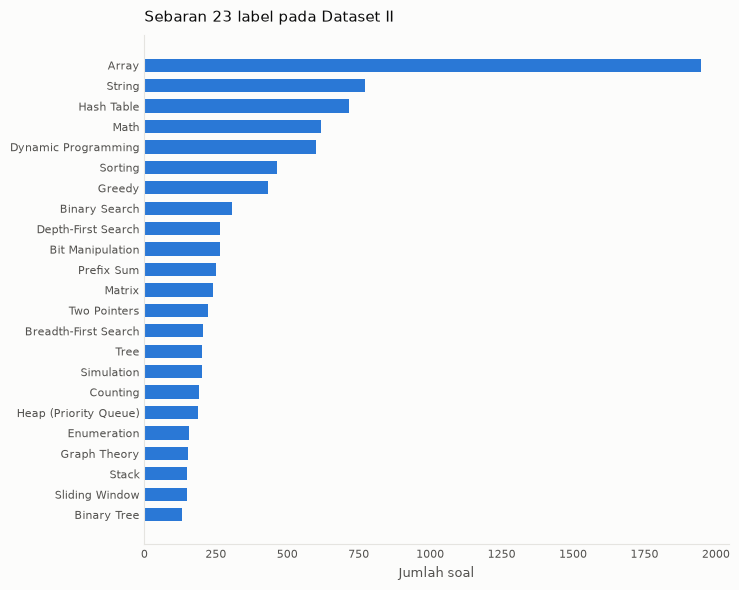

In [5]:
sebaran = pd.Series({t: sum(t in c for c in dataset2["Category"])
                     for t in label_dipakai}).sort_values(ascending=False)
sebaran.to_csv(HASIL / "sebaran_label_dataset2.csv", header=["jumlah"])

print("Sebaran 23 label")
for t, n in sebaran.items():
    print(f"  {t:<24} {n:>5}  ({100 * n / len(dataset2):>4.1f} persen soal)")
print(f"\nTerbanyak {sebaran.iloc[0]:,}, tersedikit {sebaran.iloc[-1]:,}, "
      f"rasio {sebaran.iloc[0] / sebaran.iloc[-1]:.1f}")

SURFACE, TEKS_UTAMA, TEKS_SEKUNDER, GARIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0"
fig, ax = plt.subplots(figsize=(7.5, 6), facecolor=SURFACE)
ax.barh(sebaran.index[::-1], sebaran.values[::-1], height=0.65, color="#2a78d6")
ax.set_facecolor(SURFACE)
ax.set_xlabel("Jumlah soal", fontsize=9, color=TEKS_SEKUNDER)
ax.set_title("Sebaran 23 label pada Dataset II", fontsize=11, color=TEKS_UTAMA, loc="left", pad=10)
for sisi in ("top", "right"):
    ax.spines[sisi].set_visible(False)
for sisi in ("left", "bottom"):
    ax.spines[sisi].set_color(GARIS)
ax.tick_params(colors=TEKS_SEKUNDER, length=0, labelsize=8)
plt.tight_layout()
plt.show()

**Penjelasan.** Ketimpangannya jauh lebih besar daripada Dataset I. Label terbanyak hadir di hampir enam puluh persen soal, sementara yang tersedikit hanya sekitar tiga persen. Pada klasifikasi multi-label, ketimpangan ini membuat metrik micro dan macro memberi gambaran yang berbeda, jadi keduanya perlu dilaporkan.

## Ringkasan

In [6]:
ringkas = {
    "soal_scraping": len(semua),
    "tag_asli": len(hitung),
    "rata_tag_per_soal": round(semua["tags"].apply(len).mean(), 2),
    "soal_multilabel": int((semua["tags"].apply(len) >= 2).sum()),
    "dataset1_soal": len(dataset1),
    "dataset1_kelas": dataset1["Difficulty"].nunique(),
    "dataset2_soal": len(dataset2),
    "dataset2_label": len(label_dipakai),
    "dataset2_ambang": AMBANG_LABEL,
    "dataset2_rata_label": round(dataset2["Category"].apply(len).mean(), 2),
}
pd.Series(ringkas).to_csv(HASIL / "ringkasan_dataset.csv", header=False)
for k, v in ringkas.items():
    print(f"  {k:<22} {v}")

  soal_scraping          3284
  tag_asli               173
  rata_tag_per_soal      3.3
  soal_multilabel        2903
  dataset1_soal          3284
  dataset1_kelas         3
  dataset2_soal          3094
  dataset2_label         23
  dataset2_ambang        100
  dataset2_rata_label    2.85


**Penjelasan.** Angka angka ini dipakai pada bagian deskripsi dataset di paper, dan disimpan terpisah supaya bisa dicocokkan tanpa menjalankan ulang notebook eksperimen.